In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/cleaned_churn.csv")
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [2]:
pd.DataFrame({
    "Column": df.columns,
    "Dtype": df.dtypes.astype(str),
    "Unique": df.nunique(),
    "Missing": df.isnull().sum()
})

,Column,Dtype,Unique,Missing
gender,gender,str,2,0
SeniorCitizen,SeniorCitizen,int64,2,0
Partner,Partner,str,2,0
Dependents,Dependents,str,2,0
tenure,tenure,int64,73,0
PhoneService,PhoneService,str,2,0
MultipleLines,MultipleLines,str,3,0
InternetService,InternetService,str,3,0
OnlineSecurity,OnlineSecurity,str,3,0
OnlineBackup,OnlineBackup,str,3,0


Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64


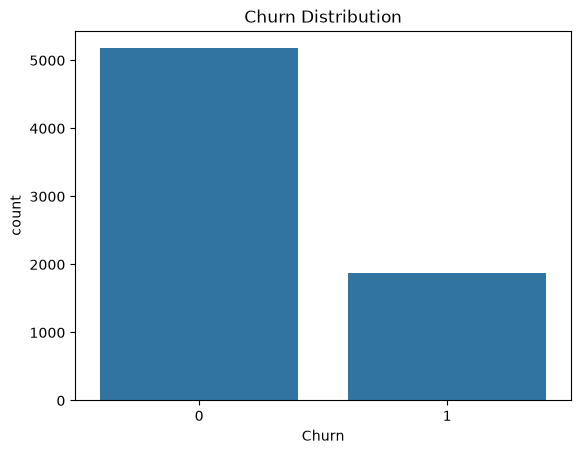

In [3]:
print(df["Churn"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="Churn")
plt.title("Churn Distribution")
plt.show()

Churn                   0          1
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


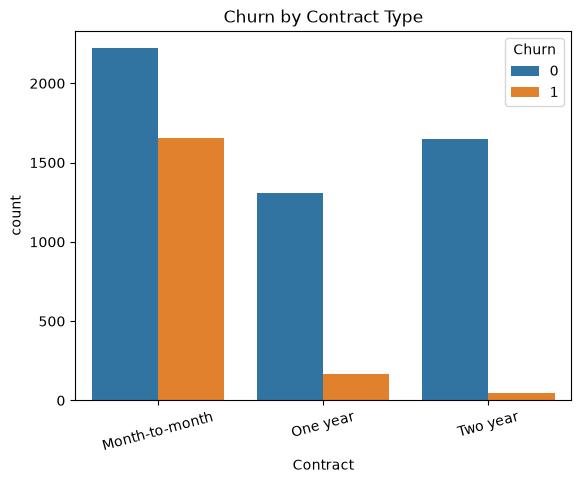

In [4]:
print(pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100)

sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.xticks(rotation=15)
plt.show()

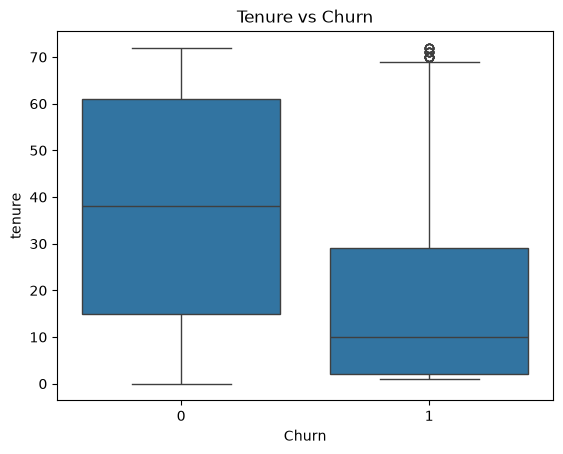

In [5]:
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Tenure vs Churn")
plt.show()

In [7]:
cat_cols = ["InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity",
            "OnlineBackup", "DeviceProtection", "StreamingTV", "StreamingMovies",
            "Partner", "Dependents", "PaperlessBilling", "PhoneService", "MultipleLines"]

for col in cat_cols:
    print(f"\n--- {col} ---")
    print(pd.crosstab(df[col], df["Churn"], normalize="index") * 100)


--- InternetService ---
Churn                    0          1
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980

--- PaymentMethod ---
Churn                              0          1
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700

--- TechSupport ---
Churn                        0          1
TechSupport                              
No                   58.364526  41.635474
No internet service  92.595020   7.404980
Yes                  84.833659  15.166341

--- OnlineSecurity ---
Churn                        0          1
OnlineSecurity                           
No                   58.233276  41.766724
No internet service  92.595020   7.404980
Yes                  85.388806  14.611194

--- Onli

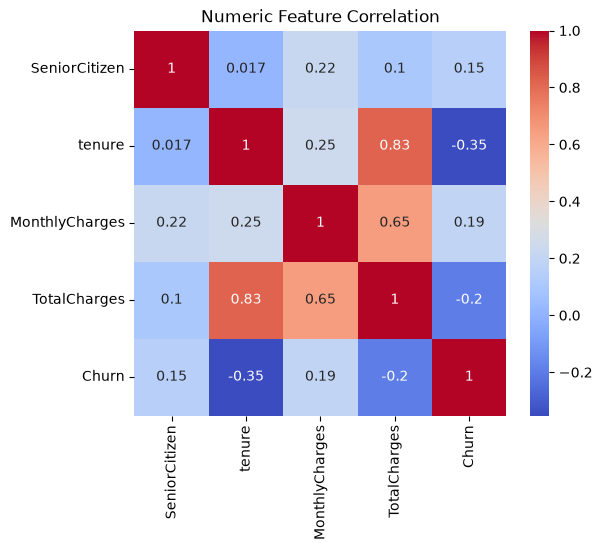

In [8]:
numeric_df = df.select_dtypes(include="number")
plt.figure(figsize=(6,5))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Numeric Feature Correlation")
plt.show()